# 06c: Three extra county datasets (cost of living, SNAP retailers, WIC)

**Why:** Q1 and Q6 found that the gap between need (Map the Meal Gap, hardship) and food shelf activity follows **access** (distance, cross-county use), not hardship. Three public datasets on the wishlist (`docs/data_wishlist.md`) can sharpen that:

| Dataset | Publisher | What it adds |
|---|---|---|
| **Cost of Living in Minnesota** | MN DEED | a basic-needs budget per county (food, housing, child care...). Hardship that income and poverty miss. |
| **Historical SNAP Retailer Locator** | USDA FNS | every store authorized to take SNAP, with location and start/end dates. Exact store counts (CBP hides counties with < 3 stores) and distance to the nearest full-service store. |
| **WIC participation by county** | MN Department of Health | how many women, infants and children use WIC: another food-assistance uptake measure. |

**Outputs** (only new files; nothing existing is changed):
- `Data/processed/county_extra_factors.csv`: county × year (2020–2025; each column only for the years its source covers).
- `Data/processed/county_extra_factors_static.csv`: county, one vintage (DEED cost of living, distance to SNAP stores).
- new rows in `county_factors_data_dictionary.csv`.

**Data rules.** The three files in `Data/new_extra_data/` were downloaded by a team member: we read them only as data (pandas, zip, PDF text). **Nothing dated August 2026 or later**: the SNAP retailer file ends in December 2025 (asserted below), WIC covers 2020–2022, DEED has no date beyond its edition.

## 1. Setup

In [1]:
from pathlib import Path
import re
import zipfile
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pypdf import PdfReader

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED = ROOT / "Data" / "processed"
LOCAL = ROOT / "Data" / "local"                 # git-ignored cache (block-group centroids, county shapes)
NEW = ROOT / "Data" / "new_extra_data"          # user-downloaded files: read as data only
CUTOFF = pd.Timestamp("2026-08-01")

fy = pd.read_csv(PROCESSED / "county_factors_2022_2024.csv", dtype={"fips": str})
mmg = pd.read_csv(PROCESSED / "mmg_mn_county_2022_2024.csv", dtype={"fips": str})
COUNTY = dict(zip(mmg["fips"], mmg["county"]))
assert len(COUNTY) == 87

def norm_name(s):
    """Upper-case county name without 'County', with Saint -> St. (matches all three sources)."""
    s = re.sub(r"\s+", " ", str(s)).strip().upper().replace(" COUNTY", "")
    s = re.sub(r"^SAINT ", "ST. ", s).replace("ST ", "ST. ") if s.startswith(("SAINT", "ST ")) else s
    return s
NAME2FIPS = {norm_name(v): k for k, v in COUNTY.items()}
print("Counties:", len(NAME2FIPS), "| example:", list(NAME2FIPS.items())[:3])

Counties: 87 | example: [('AITKIN', '27001'), ('ANOKA', '27003'), ('BECKER', '27005')]


## 2. MN DEED Cost of Living

**What the file is.** One sheet, one row per *area × family type*. We check the grain (counties? regions?) and look for a year.

In [2]:
col = pd.read_excel(NEW / "MN DEED Cost of Living.xlsx", sheet_name="Sheet1")
col["Area"] = col["Area"].str.strip()
print(col.shape, "| columns:", list(col.columns))
print("Year / date column present:", any(re.search(r"year$|date|vintage", c, re.I) and c != "Yearly Cost" for c in col.columns))
col["is_county"] = col["Area"].str.endswith(" County")
print("Areas:", col["Area"].nunique(), "=", col.loc[col["is_county"], "Area"].nunique(), "counties +",
      col.loc[~col["is_county"], "Area"].nunique(), "others:", sorted(col.loc[~col["is_county"], "Area"].unique()))
print("Rows per area:", col.groupby("Area").size().unique())
FT = ["Family Size", "Number of Adults", "Number of Workers", "Number of Children", "Age of Adults"]
print("Family types (24):")
col.drop_duplicates(FT)[FT].sort_values(FT).reset_index(drop=True).T

(2568, 15) | columns: ['Area', 'Family Size', 'Number of Adults', 'Number of Workers', 'Number of Children', 'Age of Adults', 'Yearly Cost', 'Hourly Wage', 'Child Care', 'Food', 'Health Care', 'Housing', 'Transport', 'Other', 'Taxes']
Year / date column present: False
Areas: 107 = 87 counties + 20 others: ['Central Minnesota', 'EDR  1 - Northwest', 'EDR  2 - Headwaters', 'EDR  3 - Arrowhead', 'EDR  4 - West Central', 'EDR  5 - North Central', 'EDR  6E- Southwest Central', 'EDR  6W- Upper Minnesota Valley', 'EDR  7E- East Central', 'EDR  7W- Central', 'EDR  8 - Southwest', 'EDR  9 - South Central', 'EDR 10 - Southeast', 'EDR 11 - 7 County Twin Cities', 'Minnesota', 'Northeast Minnesota', 'Northwest Minnesota', 'Seven County Mpls-St Paul, MN', 'Southeast Minnesota', 'Southwest Minnesota']
Rows per area: [24]
Family types (24):


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
Family Size,1,1,2,2,2,2,2,2,2,3,3,3,3,4,4,4,4,5,5,5,5,6,6,6
Number of Adults,1,1,1,2,2,2,2,2,2,1,2,2,2,1,2,2,2,1,2,2,2,2,2,2
Number of Workers,1.0,1.0,1.0,1.0,1.0,1.5,1.5,2.0,2.0,1.0,1.0,1.5,2.0,1.0,1.0,1.5,2.0,1.0,1.0,1.5,2.0,1.0,1.5,2.0
Number of Children,0,0,1,0,0,0,0,0,0,2,1,1,1,3,2,2,2,4,3,3,3,4,4,4
Age of Adults,19-50,51+,19-50,19-50,51+,19-50,51+,19-50,51+,19-50,19-50,19-50,19-50,19-50,19-50,19-50,19-50,19-50,19-50,19-50,19-50,19-50,19-50,19-50


**Grain:** 87 counties + the state + 19 regions (economic development regions, planning regions, the 7-county metro), **24 family types** each. **Vintage:** the file has **no year column**. DEED publishes one edition a year and the tool shows only the current one, so this is a **single cross-section** (the edition current when it was downloaded; DEED editions are built from the previous one to two years' prices). We treat it as describing roughly 2024–2025 and **never use it for year-to-year change**.

**Reference families** (fixed before looking at results):
1. **Family of 3**: 2 adults (19–50), 1 child, **1.5 workers** (one full-time, one part-time): DEED's own "typical family".
2. **Single adult**: 1 adult (19–50), no children, 1 worker.

Monthly columns (Food, Housing, Child Care...) are dollars per month; `Yearly Cost` is the full annual basic-needs budget including taxes; `Hourly Wage` is the wage **each worker** must earn to cover it.

In [3]:
cty = col[col["is_county"]].copy()
cty["fips"] = cty["Area"].map(norm_name).map(NAME2FIPS)
assert cty["fips"].notna().all() and cty["fips"].nunique() == 87, cty.loc[cty["fips"].isna(), "Area"].unique()
monthly_sum = cty[["Child Care", "Food", "Health Care", "Housing", "Transport", "Other", "Taxes"]].sum(axis=1) * 12
print("Check: 12 x sum of monthly items vs Yearly Cost, max |difference| = $",
      int((monthly_sum - cty["Yearly Cost"]).abs().max()))

REF = {"fam3": dict(adults=2, workers=1.5, children=1, age="19-50"),
       "single": dict(adults=1, workers=1.0, children=0, age="19-50")}
deed = pd.DataFrame(index=sorted(cty["fips"].unique()))
for key, r in REF.items():
    sel = cty[(cty["Number of Adults"] == r["adults"]) & (cty["Number of Workers"] == r["workers"]) &
              (cty["Number of Children"] == r["children"]) & (cty["Age of Adults"] == r["age"])].set_index("fips")
    assert len(sel) == 87 and sel.index.is_unique
    deed[f"col_yearly_cost_{key}"] = sel["Yearly Cost"]
    deed[f"col_food_monthly_{key}"] = sel["Food"]
    deed[f"col_housing_monthly_{key}"] = sel["Housing"]
    deed[f"col_required_hourly_wage_{key}"] = sel["Hourly Wage"]
deed["col_childcare_monthly_fam3"] = cty[(cty["Number of Adults"] == 2) & (cty["Number of Workers"] == 1.5) &
                                         (cty["Number of Children"] == 1) & (cty["Age of Adults"] == "19-50")].set_index("fips")["Child Care"]
# Affordability gap: basic-needs budget / median household income (SAIPE 2024 = latest year, closest to the DEED edition)
inc = fy.pivot(index="fips", columns="year", values="median_hh_income")
deed["col_affordability_gap_fam3"] = deed["col_yearly_cost_fam3"] / inc[2024]
deed["col_affordability_gap_single"] = deed["col_yearly_cost_single"] / inc[2024]
deed["col_affordability_gap_fam3_avg2224"] = deed["col_yearly_cost_fam3"] / inc[[2022, 2023, 2024]].mean(axis=1)
state = col[(col["Area"] == "Minnesota") & (col["Number of Adults"] == 2) & (col["Number of Workers"] == 1.5) &
            (col["Number of Children"] == 1) & (col["Age of Adults"] == "19-50")].iloc[0]
print(f"Minnesota, family of 3: ${state['Yearly Cost']:,} a year; food ${state['Food']:,}/month; housing ${state['Housing']:,}/month; "
      f"${state['Hourly Wage']}/hour per worker")
deed.assign(county=deed.index.map(COUNTY)).describe().T[["min", "50%", "max"]].round(2)

Check: 12 x sum of monthly items vs Yearly Cost, max |difference| = $ 6
Minnesota, family of 3: $74,616 a year; food $1,028/month; housing $1,498/month; $23.92/hour per worker


,min,50%,max
col_yearly_cost_fam3,54346.00,62304.00,82778.00
col_food_monthly_fam3,923.00,981.00,1108.00
col_housing_monthly_fam3,964.00,968.00,1741.00
col_required_hourly_wage_fam3,17.42,19.97,26.53
col_yearly_cost_single,28369.00,31154.00,42895.00
col_food_monthly_single,406.00,432.00,488.00
col_housing_monthly_single,725.00,797.00,1405.00
col_required_hourly_wage_single,13.64,14.98,20.62
col_childcare_monthly_fam3,273.00,362.00,681.00
col_affordability_gap_fam3,0.64,0.84,1.06


In [4]:
show = deed.assign(county=deed.index.map(COUNTY))[["county", "col_yearly_cost_fam3", "col_food_monthly_fam3", "col_housing_monthly_fam3",
                                                   "col_required_hourly_wage_fam3", "col_affordability_gap_fam3"]]
print("Highest affordability gap (budget / median income):"); display(show.sort_values("col_affordability_gap_fam3", ascending=False).head(6).round(2))
print("Lowest:"); display(show.sort_values("col_affordability_gap_fam3").head(4).round(2))
print("Spearman among DEED measures:")
deed[["col_yearly_cost_fam3", "col_food_monthly_fam3", "col_housing_monthly_fam3", "col_affordability_gap_fam3", "col_affordability_gap_single"]].corr(method="spearman").round(2)

Highest affordability gap (budget / median income):


,county,col_yearly_cost_fam3,col_food_monthly_fam3,col_housing_monthly_fam3,col_required_hourly_wage_fam3,col_affordability_gap_fam3
27001,Aitkin,65815,944,964,21.09,1.06
27115,Pine,71326,931,1092,22.86,1.05
27123,Ramsey,80365,1054,1741,25.76,1.02
27007,Beltrami,63427,935,1128,20.33,1.00
27065,Kanabec,71074,966,964,22.78,0.99
27087,Mahnomen,60159,950,964,19.28,0.99


Lowest:


,county,col_yearly_cost_fam3,col_food_monthly_fam3,col_housing_monthly_fam3,col_required_hourly_wage_fam3,col_affordability_gap_fam3
27079,Le Sueur,62014,981,1111,19.88,0.64
27019,Carver,82778,1062,1741,26.53,0.64
27139,Scott,81593,1021,1741,26.15,0.67
27163,Washington,81641,1047,1741,26.17,0.72


Spearman among DEED measures:


,col_yearly_cost_fam3,col_food_monthly_fam3,col_housing_monthly_fam3,col_affordability_gap_fam3,col_affordability_gap_single
col_yearly_cost_fam3,1.00,-0.04,0.68,0.08,0.06
col_food_monthly_fam3,-0.04,1.00,-0.03,-0.38,-0.36
col_housing_monthly_fam3,0.68,-0.03,1.00,-0.18,-0.08
col_affordability_gap_fam3,0.08,-0.38,-0.18,1.00,0.93
col_affordability_gap_single,0.06,-0.36,-0.08,0.93,1.00


**What this shows.**
- **Budget:** a family of 3 needs about **$62,300 a year** in the median county (range $54,346 to $82,778; Minnesota as a whole $74,616). The 7-county metro is the most expensive (Carver $82,778).
- **Affordability gap** (budget ÷ median household income, SAIPE 2024): median county **0.84**, range **0.64 to 1.06**. It is highest where incomes are low, not where costs are high: **Aitkin 1.06, Pine 1.05, Ramsey 1.02, Beltrami 1.00**, Kanabec and Mahnomen 0.99, i.e. the typical household there earns about the family-of-3 budget or less. Lowest: Le Sueur and Carver 0.64. The budget itself and the gap are almost unrelated across counties (ρ = 0.08), so they measure different things.
- **Food costs vary less than housing:** food $923 to $1,108 a month for the family of 3, and food is *cheaper* where hardship is higher (ρ = −0.38 with the affordability gap). Housing is $964 a month in most rural counties (a floor) and $1,741 in the metro.
- Using the 2022–2024 average income instead of 2024 barely changes the gap ranking (printed below).

In [5]:
print("Spearman, affordability gap with 2024 income vs 2022-2024 average income:",
      round(deed["col_affordability_gap_fam3"].corr(deed["col_affordability_gap_fam3_avg2224"], method="spearman"), 3))

Spearman, affordability gap with 2024 income vs 2022-2024 average income: 0.941


## 3. USDA FNS Historical SNAP Retailer Locator (2005–2025)

One CSV in a zip: every store ever authorized for SNAP since 2005, with **store type**, address, **county name**, latitude/longitude and **authorization / end dates**. A blank end date means the store is still authorized.

**Steps:**
1. Read Minnesota (for counts) and the four neighbouring states (for distance only: a Moorhead resident can shop in Fargo).
2. **Active on 1 July** of each year 2022–2025: authorized on or before that date and not ended by it.
3. Store type groups:
   - **full-service** = Supermarket, Super Store, Large Grocery Store (the store types USDA ERS counts as supermarkets/large grocery in its food access maps);
   - **small grocery** = Medium Grocery, Small Grocery, Combination Grocery/Other;
   - **convenience** = Convenience Store;
   - **other** = specialty (meat, bakery, produce, seafood), farmers' markets, delivery routes, co-ops, unknown.
4. County: from the file's `County` name; checked against the store's coordinates with point-in-polygon in the Census county shapes (cached in `Data/local/`).

In [6]:
zf = zipfile.ZipFile(NEW / "snap-retailer-locator-data2005-2025.zip")
print([(i.filename, f"{i.file_size / 1e6:.0f} MB") for i in zf.infolist()])
with zf.open(zf.namelist()[0]) as fh:
    ret_all = pd.read_csv(fh, encoding="latin-1", dtype=str)
ret_all.columns = [c.replace("ï»¿", "").replace("﻿", "").strip() for c in ret_all.columns]
for c in ["Store Name", "Store Type", "State", "County"]:
    ret_all[c] = ret_all[c].str.strip()
for c in ["Authorization Date", "End Date"]:
    ret_all[c] = pd.to_datetime(ret_all[c].str.strip(), format="%m/%d/%Y", errors="coerce")
ret_all["lat"] = pd.to_numeric(ret_all["Latitude"], errors="coerce")
ret_all["lon"] = pd.to_numeric(ret_all["Longitude"], errors="coerce")
print(f"All rows: {len(ret_all):,} | latest authorization date: {ret_all['Authorization Date'].max().date()} | latest end date: {ret_all['End Date'].max().date()}")
# Hard rule: nothing dated August 2026 or later
assert ret_all["Authorization Date"].max() < CUTOFF and ret_all["End Date"].max() < CUTOFF
assert ret_all["Authorization Date"].max() <= pd.Timestamp("2025-12-31")

ret = ret_all[ret_all["State"] == "MN"].copy()
nbr = ret_all[ret_all["State"].isin(["ND", "SD", "IA", "WI"])].copy()
print(f"Minnesota rows: {len(ret):,} ({ret['Record ID'].nunique():,} record IDs) | neighbouring-state rows: {len(nbr):,}")
print("Unparsed authorization dates (MN):", ret["Authorization Date"].isna().sum(), "| missing/zero coordinates (MN):",
      int(((ret["lat"].fillna(0) == 0) | (ret["lon"].fillna(0) == 0)).sum()))
ret["Store Type"].value_counts()

[('Historical SNAP Retailer Locator Data 2005-2025.csv', '95 MB')]
All rows: 703,441 | latest authorization date: 2025-12-31 | latest end date: 2025-12-31
Minnesota rows: 8,524 (8,078 record IDs) | neighbouring-state rows: 19,865
Unparsed authorization dates (MN): 0 | missing/zero coordinates (MN): 41


Store Type
Convenience Store            3710
Combination Grocery/Other    1157
Medium Grocery Store          758
Small Grocery Store           605
Super Store                   560
Supermarket                   481
Bakery Specialty              338
Meat/Poultry Specialty        278
Farmers' Market               252
Large Grocery Store           221
Fruits/Veg Specialty           62
Delivery Route                 59
Food Buying Co-op              25
Unknown                        12
Seafood Specialty               6
Name: count, dtype: int64

In [7]:
TYPE_GROUP = {"Supermarket": "full_service", "Super Store": "full_service", "Large Grocery Store": "full_service",
              "Medium Grocery Store": "small_grocery", "Small Grocery Store": "small_grocery", "Combination Grocery/Other": "small_grocery",
              "Convenience Store": "convenience"}
for d_ in (ret, nbr):
    d_["type_group"] = d_["Store Type"].map(TYPE_GROUP).fillna("other")

# County: from the name in the file, checked against coordinates (point in polygon)
ret["fips_name"] = ret["County"].map(norm_name).map(NAME2FIPS)
print("Rows whose county name doesn't match an MN county:", ret.loc[ret["fips_name"].isna(), "County"].value_counts().to_dict())
import geopandas as gpd
shp = gpd.read_file(LOCAL / "cb_2023_us_county_500k.zip")
mn_shp = shp[shp["STATEFP"] == "27"][["GEOID", "geometry"]].to_crs(4326)
has_xy = ret["lat"].between(43, 50) & ret["lon"].between(-98, -89)
pts = gpd.GeoDataFrame(ret[has_xy][["Record ID"]], geometry=gpd.points_from_xy(ret.loc[has_xy, "lon"], ret.loc[has_xy, "lat"]), crs=4326)
ret.loc[has_xy, "fips_pip"] = gpd.sjoin(pts, mn_shp, how="left", predicate="within")["GEOID"].groupby(level=0).first()
both = ret["fips_name"].notna() & ret["fips_pip"].notna()
print(f"Name and coordinates agree for {(ret.loc[both, 'fips_name'] == ret.loc[both, 'fips_pip']).mean():.1%} of {both.sum():,} rows")
ret["fips"] = ret["fips_name"].fillna(ret["fips_pip"])
print("Rows with no county after both methods:", int(ret["fips"].isna().sum()))

Rows whose county name doesn't match an MN county: {}
Name and coordinates agree for 99.0% of 8,483 rows
Rows with no county after both methods: 0


In [8]:
DATES = {y: pd.Timestamp(f"{y}-07-01") for y in [2022, 2023, 2024, 2025]}
def active(df, when):
    return (df["Authorization Date"] <= when) & (df["End Date"].isna() | (df["End Date"] > when))

rows = []
for y, when in DATES.items():
    a = ret[active(ret, when) & ret["fips"].notna()].drop_duplicates("Record ID")
    c = a.groupby(["fips", "type_group"]).size().unstack(fill_value=0)
    c["all"] = c.sum(axis=1)
    rows.append(c.reindex(sorted(COUNTY), fill_value=0).assign(year=y))
cnt = pd.concat(rows).reset_index().rename(columns={"index": "fips"})
cnt = cnt.rename(columns={"all": "snap_retailers", "full_service": "snap_full_service", "small_grocery": "snap_small_grocery",
                          "convenience": "snap_convenience", "other": "snap_other"})
# Population: Census PEP (2022-2024 from county_factors; 2025 not published in Vintage 2024 -> reuse 2024 and flag)
pop = fy[["fips", "year", "pop_pep"]]
pop25 = pop[pop["year"] == 2024].assign(year=2025)
cnt = cnt.merge(pd.concat([pop, pop25]), on=["fips", "year"], how="left", validate="one_to_one")
for c in ["snap_retailers", "snap_full_service", "snap_small_grocery", "snap_convenience"]:
    cnt[f"{c}_per_10k"] = cnt[c] / cnt["pop_pep"] * 1e4
cnt["snap_pop_is_2024_proxy"] = cnt["year"] == 2025
print("Statewide SNAP retailers active on 1 July:")
display(cnt.groupby("year")[["snap_retailers", "snap_full_service", "snap_small_grocery", "snap_convenience", "snap_other"]].sum())
print("Counties with 0 full-service SNAP stores on 1 July 2024:",
      sorted(COUNTY[f] for f in cnt[(cnt["year"] == 2024) & (cnt["snap_full_service"] == 0)]["fips"]))

Statewide SNAP retailers active on 1 July:


,snap_retailers,snap_full_service,snap_small_grocery,snap_convenience,snap_other
year,,,,,
2022,3510,772,1001,1441,296
2023,3576,776,1031,1455,314
2024,3634,796,1048,1466,324
2025,3612,799,1049,1463,301


Counties with 0 full-service SNAP stores on 1 July 2024: ['Red Lake']


**Check against County Business Patterns** (grocery stores with employees, NAICS 445110; available 2022–2023): the two count different things (CBP: establishments with payroll in "supermarkets and other grocery"; SNAP: any store authorized to take SNAP, including convenience stores and gas stations), so we expect a strong but imperfect rank agreement.

In [9]:
cbp = fy[fy["year"].isin([2022, 2023])][["fips", "year", "n_grocery_stores", "grocery_count_lt3"]]
cc = cbp.merge(cnt, on=["fips", "year"])
cc["snap_grocery"] = cc["snap_full_service"] + cc["snap_small_grocery"]
ok = cc["n_grocery_stores"].notna()
print(f"Spearman, CBP grocery stores vs SNAP full-service + small grocery (county-years with a CBP count, n={ok.sum()}): "
      f"{cc.loc[ok, 'n_grocery_stores'].corr(cc.loc[ok, 'snap_grocery'], method='spearman'):.2f}")
supp = cc[cc["grocery_count_lt3"].astype(str).str.upper().eq("TRUE")]
print(f"CBP-suppressed county-years (<3 stores): {len(supp)}; SNAP full-service stores there: median {supp['snap_full_service'].median():.0f}, "
      f"SNAP grocery (full + small) median {supp['snap_grocery'].median():.0f}: the SNAP file fills CBP's blanks with exact counts.")

Spearman, CBP grocery stores vs SNAP full-service + small grocery (county-years with a CBP count, n=139): 0.82
CBP-suppressed county-years (<3 stores): 35; SNAP full-service stores there: median 2, SNAP grocery (full + small) median 4: the SNAP file fills CBP's blanks with exact counts.


**What this shows.**
- **County assignment is reliable:** every Minnesota row's county name matches one of the 87 counties, and the name agrees with the store's coordinates for 99.0% of rows (the rest sit on or near a county line).
- **Counts:** 3,510 SNAP retailers were active on 1 July 2022, 3,634 in 2024 and 3,612 in 2025; **full-service** stores (supermarket, super store, large grocery) 772 → 796 → 799. About 4 in 10 SNAP retailers are convenience stores.
- **Red Lake** is the only county with **no** full-service SNAP store in 2024.
- **CBP check:** the SNAP grocery count (full-service + small grocery) ranks counties like CBP's grocery count (Spearman 0.82), and it gives exact numbers in the 35 county-years CBP suppresses (median 2 full-service and 4 grocery stores there).

### 3b. Openings and closings, 2022 → 2025

Net change = active on 1 July 2025 − active on 1 July 2022, per county (all SNAP retailers and full-service only). Also the counts of stores **closing** (end date between the two dates) and **opening** (authorized between them), so a stable net number can be told apart from high churn.

In [10]:
t0, t1 = DATES[2022], DATES[2025]
w = cnt.pivot(index="fips", columns="year", values=["snap_retailers", "snap_full_service"])
chg = pd.DataFrame({"snap_net_change_2022_2025": w[("snap_retailers", 2025)] - w[("snap_retailers", 2022)],
                    "snap_full_net_change_2022_2025": w[("snap_full_service", 2025)] - w[("snap_full_service", 2022)]})
base = ret[ret["fips"].notna()].drop_duplicates("Record ID", keep="last")
closed = base[active(base, t0) & base["End Date"].notna() & (base["End Date"] <= t1)]
opened = base[(base["Authorization Date"] > t0) & (base["Authorization Date"] <= t1)]
chg["snap_closed_2022_2025"] = closed.groupby("fips").size().reindex(chg.index, fill_value=0)
chg["snap_opened_2022_2025"] = opened.groupby("fips").size().reindex(chg.index, fill_value=0)
chg["snap_full_closed_2022_2025"] = closed[closed["type_group"] == "full_service"].groupby("fips").size().reindex(chg.index, fill_value=0)
p24 = pop.query("year == 2024").set_index("fips")["pop_pep"]
chg["snap_net_change_per_10k_2022_2025"] = chg["snap_net_change_2022_2025"] / p24 * 1e4
chg["snap_pct_change_2022_2025"] = chg["snap_net_change_2022_2025"] / w[("snap_retailers", 2022)] * 100
print("Statewide: net change", int(chg["snap_net_change_2022_2025"].sum()), "| closed", int(chg["snap_closed_2022_2025"].sum()),
      "| opened", int(chg["snap_opened_2022_2025"].sum()), "| full-service net", int(chg["snap_full_net_change_2022_2025"].sum()),
      "| full-service closed", int(chg["snap_full_closed_2022_2025"].sum()))
print("Counties that lost at least one full-service SNAP store (net):",
      {COUNTY[f]: int(v) for f, v in chg["snap_full_net_change_2022_2025"].items() if v < 0})
chg.assign(county=chg.index.map(COUNTY)).sort_values("snap_pct_change_2022_2025")[["county", "snap_net_change_2022_2025", "snap_pct_change_2022_2025",
                                                                                     "snap_closed_2022_2025", "snap_opened_2022_2025"]].head(8).round(1)

Statewide: net change 102 | closed 641 | opened 914 | full-service net 27 | full-service closed 50
Counties that lost at least one full-service SNAP store (net): {'Crow Wing': -1, 'Marshall': -1, 'Ramsey': -3, 'St. Louis': -1, 'Scott': -1, 'Waseca': -2, 'Wright': -1}


,county,snap_net_change_2022_2025,snap_pct_change_2022_2025,snap_closed_2022_2025,snap_opened_2022_2025
fips,,,,,
27151,Swift,-3,-27.3,4,1
27167,Wilkin,-1,-25.0,2,1
27087,Mahnomen,-1,-12.5,2,2
27161,Waseca,-2,-11.8,4,3
27009,Benton,-4,-11.4,15,12
27089,Marshall,-1,-11.1,3,2
27091,Martin,-2,-9.5,6,6
27159,Wadena,-1,-7.7,1,2


**What this shows.** Statewide the SNAP network **grew slightly**: 914 stores were authorized and 641 left between July 2022 and July 2025 (net **+102**; full-service net +27, with 50 full-service stores leaving). Net losses of full-service stores are small and scattered (Ramsey −3, Waseca −2, five counties −1). The largest relative net losses of SNAP retailers are in small counties: Swift −27% (−3 stores), Wilkin −25% (−1), Mahnomen, Waseca, Benton, Marshall (−11 to −13%). With such small numbers, "closures" are a weak county signal.

### 3c. Distance to the nearest SNAP-authorized store (where people live)

Same approach as Q1 section 28a (food shelf distance) and Q6 section 11: **Census 2020 population-weighted centers of Minnesota's 4,706 block groups** (`Data/local/CenPop2020_Mean_BG27.txt`), straight-line (great-circle) miles to the nearest store, averaged over each county's block groups weighted by population. Stores active on **1 July 2024** (the last year of the Q1/Q6 window); 2022 as a check. Stores just across the state line count (ND, SD, IA, WI), because people shop there.

Measures: average miles to the nearest **full-service** SNAP store, % of residents more than **10 miles** from one, and average miles to the nearest **any** SNAP store.

In [11]:
bgpop = pd.read_csv(LOCAL / "CenPop2020_Mean_BG27.txt", encoding="utf-8-sig", dtype=str)
bgpop = bgpop.assign(fips=bgpop["STATEFP"] + bgpop["COUNTYFP"], population=bgpop["POPULATION"].astype(int),
                     lat=bgpop["LATITUDE"].astype(float), lon=bgpop["LONGITUDE"].astype(float))

def miles(lat1, lon1, lat2, lon2):
    """Straight-line (great-circle) distance in miles (same function as Q1 section 28a)."""
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 3958.8 * 2 * np.arcsin(np.sqrt(a))

stores_all = pd.concat([ret, nbr])
stores_all = stores_all[stores_all["lat"].between(40, 50) & stores_all["lon"].between(-105, -85)]

def nearest_measures(when, types, tag):
    s = stores_all[active(stores_all, when)].drop_duplicates("Record ID")
    if types is not None:
        s = s[s["type_group"].isin(types)]
    d = miles(bgpop["lat"].values[:, None], bgpop["lon"].values[:, None], s["lat"].values[None, :], s["lon"].values[None, :]).min(axis=1)
    bg = bgpop.assign(d=d * bgpop["population"], f=(d > 10) * bgpop["population"])
    agg = bg.groupby("fips")[["d", "f", "population"]].sum()
    return pd.DataFrame({f"{tag}_mean_dist_mi": agg["d"] / agg["population"],
                         f"{tag}_pct_over_10mi": agg["f"] / agg["population"] * 100}), len(s)

dist24, n_full24 = nearest_measures(DATES[2024], ["full_service"], "snap_full")
dist22, n_full22 = nearest_measures(DATES[2022], ["full_service"], "snap_full")
dany24, n_any24 = nearest_measures(DATES[2024], None, "snap_any")
print(f"Stores used (MN + neighbours): full-service 2024 = {n_full24:,}, 2022 = {n_full22:,}; any SNAP store 2024 = {n_any24:,}")
print("Spearman, county average distance to full-service store 2024 vs 2022:",
      round(dist24["snap_full_mean_dist_mi"].corr(dist22["snap_full_mean_dist_mi"], method="spearman"), 3))
q1p = pd.read_csv(PROCESSED / "q1_county_profiles.csv", dtype={"fips": str}).set_index("fips")
st = pd.read_csv(PROCESSED / "county_factors_static.csv", dtype={"fips": str}).set_index("fips")
print("Spearman with distance to the nearest FOOD SHELF (Q1):", round(dist24["snap_full_mean_dist_mi"].corr(q1p["mean_dist_mi"], method="spearman"), 2),
      "| with USDA ERS SRAM 2025 % low access 1/10 mi (any SNAP store):",
      round(dist24["snap_full_pct_over_10mi"].corr(st["sram_pct_low_access_1_10"], method="spearman"), 2) if "sram_pct_low_access_1_10" in st else "n/a",
      "| with USDA FARA 2019 % low access to a supermarket:", round(dist24["snap_full_mean_dist_mi"].corr(st["fara_pct_low_access_1_10"], method="spearman"), 2))
dist24.join(dany24).describe().round(1)

Stores used (MN + neighbours): full-service 2024 = 2,353, 2022 = 2,301; any SNAP store 2024 = 12,326
Spearman, county average distance to full-service store 2024 vs 2022: 0.958
Spearman with distance to the nearest FOOD SHELF (Q1): 0.71 | with USDA ERS SRAM 2025 % low access 1/10 mi (any SNAP store): -0.04 | with USDA FARA 2019 % low access to a supermarket: 0.29


,snap_full_mean_dist_mi,snap_full_pct_over_10mi,snap_any_mean_dist_mi,snap_any_pct_over_10mi
count,87.0,87.0,87.0,87.0
mean,4.3,12.5,2.4,1.9
std,2.1,14.5,1.2,4.9
min,0.7,0.0,0.4,0.0
25%,2.9,0.0,1.6,0.0
50%,4.0,8.7,2.3,0.0
75%,5.2,19.9,3.0,0.4
max,11.7,66.4,6.7,27.2


**What this shows.**
- In the median county, residents live on average **4.0 miles** from the nearest full-service SNAP store (range 0.7 to 11.7), and **8.7%** of residents live more than 10 miles away (up to 66%). The nearest **any** SNAP store (often a convenience store or gas station) is much closer: 2.3 miles in the median county.
- The ranking is stable over time (2024 vs 2022: Spearman 0.96).
- Distance to a full-service SNAP store tracks distance to a **food shelf** (Q1) quite closely (ρ = 0.71): remote counties are remote for both. That matters when interpreting Q6: the two cannot be cleanly separated.
- It agrees only loosely with USDA's older supermarket-access share (FARA 2019, ρ = 0.29) and not at all with SRAM 2025's "low access to any SNAP store" share (ρ = −0.04), which counts small stores; ours is a population-weighted distance to **full-service** stores, a different measure.

## 4. WIC participation by county (MN Department of Health), 2020–2022

Three PDFs: *Calendar Year Unduplicated Minnesota WIC Participation Count by County of Residence* (Minnesota WIC Information System). One row per county: total participants, then women (pregnant / postpartum, by breastfeeding), infants (by feeding type) and **children** (ages 1–4), each with a share in brackets. "Unduplicated" = a person who used WIC in any month of the calendar year counts once.

We extract the text with `pypdf` (no table tool needed: each county is one text line) and parse the numbers. Only **Total, Women, Infants, Children** are kept; the breastfeeding sub-categories are not needed.

In [12]:
NUM = r"(\d[\d,]*)"
def parse_wic(path):
    """One county per text line: NAME total women (x) ... infants (x) ... children (x). Returns Total/Women/Infants/Children."""
    lines = []
    for page in PdfReader(path).pages:
        lines += page.extract_text().splitlines()
    rows, carry = [], ""
    for ln in lines:
        ln = (carry + " " + ln.strip()).strip() if carry else ln.strip()
        carry = ""
        if re.fullmatch(r"[A-Z][A-Z .]*", ln):          # county name wrapped onto two lines ("LAKE OF THE" / "WOODS 106 ...")
            carry = ln
            continue
        m = re.match(r"^([A-Z][A-Z .]*?)\s+(\d.*)$", ln)
        if not m:
            continue
        body = re.sub(r"\([^)]*\)", " ", m.group(2))   # drop the (share) brackets, incl. suppressed "(****)"
        nums = [int(x.replace(",", "")) for x in re.findall(NUM, body)]
        if len(nums) != 13:                              # total, women + 5 sub-groups, infants + 4, children
            print("  skipped (unexpected layout):", ln[:60])
            continue
        rows.append({"name": m.group(1).strip(), "wic_participants": nums[0], "wic_women": nums[1], "wic_infants": nums[7], "wic_children": nums[12]})
    return pd.DataFrame(rows)

wic_rows = []
for y in [2020, 2021, 2022]:
    w_ = parse_wic(NEW / f"{y}county_WIC participation.pdf").assign(year=y)
    st_row = w_[w_["name"] == "MINNESOTA"].drop_duplicates()
    w_ = w_[w_["name"] != "MINNESOTA"].drop_duplicates()
    w_["fips"] = w_["name"].map(norm_name).map(NAME2FIPS)
    bad = w_[w_["fips"].isna()]
    sums_ok = (w_["wic_women"] + w_["wic_infants"] + w_["wic_children"] == w_["wic_participants"]).mean()
    print(f"{y}: parsed {len(w_)} county rows | unmatched names: {bad['name'].tolist()} | "
          f"women + infants + children = total in {sums_ok:.0%} of rows | statewide total {int(st_row['wic_participants'].iloc[0]):,}, "
          f"sum of counties {w_['wic_participants'].sum():,}")
    wic_rows.append(w_)
wic = pd.concat(wic_rows, ignore_index=True)
assert wic.groupby("year")["fips"].nunique().eq(87).all() and not wic.duplicated(["fips", "year"]).any()
wic.groupby("year")[["wic_participants", "wic_women", "wic_infants", "wic_children"]].sum()

2020: parsed 87 county rows | unmatched names: [] | women + infants + children = total in 100% of rows | statewide total 156,763, sum of counties 156,763
2021: parsed 87 county rows | unmatched names: [] | women + infants + children = total in 100% of rows | statewide total 153,383, sum of counties 153,383
2022: parsed 87 county rows | unmatched names: [] | women + infants + children = total in 100% of rows | statewide total 156,603, sum of counties 156,603


,wic_participants,wic_women,wic_infants,wic_children
year,,,,
2020,156763,42429,45480,68854
2021,153383,40693,42806,69884
2022,156603,42376,43064,71163


**Extraction worked for all three years**: 87 counties each, every county name matched, women + infants + children equals the total in every row, and the county sum equals the statewide total exactly (2020: 156,763; 2021: 153,383; 2022: 156,603 participants).

**Denominators.**
- **Per 1,000 residents:** Census PEP July population of the same year (2020–2021 from the Vintage 2024 file already in `Data/external/public_factors/raw/popest/`; 2022 from `county_factors_2022_2024.csv`).
- **Infants + children per 100 children under 5:** ACS 5-year 2018–22 table B09001 (lines 3 + 4: under 3 years and 3–4 years, in households), cached in `Data/external/public_factors/raw/census_acs/` by `06b`. One window for all three years (it is centred on 2020), so this rate is approximate.

WIC eligibility is ≤ 185% of poverty (or on Medicaid/SNAP), so this is a **program-uptake** measure: it mixes need (how many young children are low-income) with reach (how many of them enrol). It is **not** used as a need component; Q6 uses it as a validation check.

In [13]:
pe = pd.read_csv(ROOT / "Data" / "external" / "public_factors" / "raw" / "popest" / "co-est2024-alldata.csv", encoding="latin-1", dtype=str)
pe = pe[(pe["STATE"] == "27") & (pe["COUNTY"] != "000")].assign(fips=lambda d: d["STATE"] + d["COUNTY"])
pep = pe.melt(id_vars="fips", value_vars=["POPESTIMATE2020", "POPESTIMATE2021", "POPESTIMATE2022"], var_name="v", value_name="pop")
pep["year"] = pep["v"].str[-4:].astype(int); pep["pop"] = pep["pop"].astype(int)
chk = pep[pep["year"] == 2022].set_index("fips")["pop"].sub(fy[fy["year"] == 2022].set_index("fips")["pop_pep"]).abs().max()
print("PEP 2022 matches county_factors pop_pep: max |difference| =", chk)

import json
acs = json.load(open(ROOT / "Data" / "external" / "public_factors" / "raw" / "census_acs" / "acs5_2022_B09001_mn_county.json"))
acs = pd.DataFrame(acs[1:], columns=acs[0])
acs["fips"] = acs["state"] + acs["county"]
acs["pop_under5_acs"] = acs["B09001_003E"].astype(int) + acs["B09001_004E"].astype(int)

wic = wic.merge(pep[["fips", "year", "pop"]], on=["fips", "year"], validate="one_to_one").merge(acs[["fips", "pop_under5_acs"]], on="fips", validate="many_to_one")
wic["wic_per_1k_residents"] = wic["wic_participants"] / wic["pop"] * 1000
wic["wic_infants_children_per_100_under5"] = (wic["wic_infants"] + wic["wic_children"]) / wic["pop_under5_acs"] * 100
print("Statewide WIC infants+children per 100 children under 5:",
      (wic.groupby("year").apply(lambda g: (g["wic_infants"] + g["wic_children"]).sum() / g["pop_under5_acs"].sum() * 100, include_groups=False)).round(1).to_dict())
print("Year-to-year stability of the per-child rate (Spearman 2020 vs 2022):",
      round(wic.pivot(index="fips", columns="year", values="wic_infants_children_per_100_under5").corr(method="spearman").loc[2020, 2022], 2))
wic.groupby("year")[["wic_per_1k_residents", "wic_infants_children_per_100_under5"]].describe().round(1).T

PEP 2022 matches county_factors pop_pep: max |difference| = 0
Statewide WIC infants+children per 100 children under 5: {2020: 33.7, 2021: 33.2, 2022: 33.6}
Year-to-year stability of the per-child rate (Spearman 2020 vs 2022): 0.93


year                                       2020  2021  2022
wic_per_1k_residents                count  87.0  87.0  87.0
                                    mean   32.4  31.5  32.4
                                    std    11.8  11.5  11.8
                                    min     9.6   9.5   9.9
                                    25%    25.3  24.0  24.9
                                    50%    29.5  30.0  30.8
                                    75%    37.4  36.6  36.9
                                    max    85.1  81.1  81.6
wic_infants_children_per_100_under5 count  87.0  87.0  87.0
                                    mean   40.8  40.0  40.8
                                    std    11.3  10.7  10.9
                                    min    11.7  11.5  12.3
                                    25%    33.2  32.8  34.1
                                    50%    40.9  39.9  41.2
                                    75%    47.5  46.6  46.8
                                    max    79.8  73.6  75.9

**What this shows.** About **1 in 3** Minnesota children under 5 is on WIC (33.6 infants + children per 100 children under 5 statewide in 2022); in the median county 41 per 100 (range 12 to 76). Per resident: median county 31 participants per 1,000 (2022). County rankings are very stable from 2020 to 2022 (Spearman 0.93), so the missing 2023–2024 years are less of a problem for a cross-county comparison.

## 5. Save

- **`county_extra_factors.csv`**: one row per county × year, **2020–2025** (87 × 6 = 522 rows). WIC columns are filled for 2020–2022 only; SNAP retailer columns for 2022–2025 only (blank = not covered, not zero).
- **`county_extra_factors_static.csv`**: one row per county: DEED cost of living (one edition), SNAP store distance (stores active 1 July 2024; 2022 check), net change / openings / closings 2022→2025.
- Data dictionary rows appended to `county_factors_data_dictionary.csv` (existing rows asserted unchanged).

In [14]:
panel = pd.MultiIndex.from_product([sorted(COUNTY), range(2020, 2026)], names=["fips", "year"]).to_frame(index=False)
panel["county"] = panel["fips"].map(COUNTY)
WIC_COLS = ["wic_participants", "wic_women", "wic_infants", "wic_children", "wic_per_1k_residents", "wic_infants_children_per_100_under5"]
SNAP_COLS = ["snap_retailers", "snap_full_service", "snap_small_grocery", "snap_convenience", "snap_other",
             "snap_retailers_per_10k", "snap_full_service_per_10k", "snap_small_grocery_per_10k", "snap_convenience_per_10k", "snap_pop_is_2024_proxy"]
extra = (panel.merge(wic[["fips", "year"] + WIC_COLS], on=["fips", "year"], how="left")
              .merge(cnt[["fips", "year"] + SNAP_COLS], on=["fips", "year"], how="left"))
assert len(extra) == 87 * 6 and not extra.duplicated(["fips", "year"]).any()
assert extra.loc[extra["year"].between(2020, 2022), "wic_participants"].notna().all()
assert extra.loc[extra["year"].between(2022, 2025), "snap_retailers"].notna().all()
extra.round(4).to_csv(PROCESSED / "county_extra_factors.csv", index=False)

static = (deed.join(dist24).join(dist22.add_suffix("_2022")).join(dany24).join(chg)
          .rename(columns={"snap_full_mean_dist_mi": "snap_full_mean_dist_mi_2024", "snap_full_pct_over_10mi": "snap_full_pct_over_10mi_2024",
                           "snap_any_mean_dist_mi": "snap_any_mean_dist_mi_2024", "snap_any_pct_over_10mi": "snap_any_pct_over_10mi_2024",
                           "snap_full_mean_dist_mi_2022": "snap_full_mean_dist_mi_2022", "snap_full_pct_over_10mi_2022": "snap_full_pct_over_10mi_2022"}))
static.index.name = "fips"
static = static.reset_index()
static.insert(1, "county", static["fips"].map(COUNTY))
assert len(static) == 87 and static["fips"].is_unique and static.drop(columns=["fips", "county"]).notna().all().all()
static.round(4).to_csv(PROCESSED / "county_extra_factors_static.csv", index=False)
print("Saved county_extra_factors.csv", extra.shape, "| county_extra_factors_static.csv", static.shape)
print(list(static.columns))

Saved county_extra_factors.csv (522, 19) | county_extra_factors_static.csv (87, 27)
['fips', 'county', 'col_yearly_cost_fam3', 'col_food_monthly_fam3', 'col_housing_monthly_fam3', 'col_required_hourly_wage_fam3', 'col_yearly_cost_single', 'col_food_monthly_single', 'col_housing_monthly_single', 'col_required_hourly_wage_single', 'col_childcare_monthly_fam3', 'col_affordability_gap_fam3', 'col_affordability_gap_single', 'col_affordability_gap_fam3_avg2224', 'snap_full_mean_dist_mi_2024', 'snap_full_pct_over_10mi_2024', 'snap_full_mean_dist_mi_2022', 'snap_full_pct_over_10mi_2022', 'snap_any_mean_dist_mi_2024', 'snap_any_pct_over_10mi_2024', 'snap_net_change_2022_2025', 'snap_full_net_change_2022_2025', 'snap_closed_2022_2025', 'snap_opened_2022_2025', 'snap_full_closed_2022_2025', 'snap_net_change_per_10k_2022_2025', 'snap_pct_change_2022_2025']


In [15]:
# Data dictionary: append rows for the two new files (existing rows must stay exactly the same)
dd_path = PROCESSED / "county_factors_data_dictionary.csv"
dd_old = pd.read_csv(dd_path, dtype=str, keep_default_na=False)
dd_old = dd_old[~dd_old["file"].isin(["county_extra_factors.csv", "county_extra_factors_static.csv"])]   # re-runnable
DEED_SRC = "MN DEED, Cost of Living in Minnesota (download from mn.gov/deed/data/data-tools/col/), Sheet1"
DEED_V = "single edition, no year in file (current edition at download; DEED builds it from the prior 1-2 years' costs)"
SNAP_SRC = "USDA FNS, Historical SNAP Retailer Locator Data 2005-2025 (snap-retailer-locator-data2005-2025.zip)"
SNAP_V = "store records 2005 - 31 Dec 2025; counts as of 1 July each year"
WIC_SRC = "MN Department of Health WIC Program, CY Unduplicated Minnesota WIC Participation Count by County of Residence (PDF, MN WIC Information System)"
F1, F2 = "county_extra_factors.csv", "county_extra_factors_static.csv"
rows = [
 (F1, "fips", "5-digit county FIPS code, read as TEXT; join key", "text", "-", "-", "county", "annual"),
 (F1, "year", "Calendar year (2020-2025); WIC columns filled 2020-2022, SNAP retailer columns 2022-2025", "year", "-", "-", "county", "annual"),
 (F1, "county", "County name", "text", "-", "-", "county", "annual"),
 (F1, "wic_participants", "WIC participants in the calendar year, unduplicated (anyone enrolled in any month), by county of residence", "persons", WIC_SRC, "CY2020, CY2021, CY2022", "county", "annual (2020-2022)"),
 (F1, "wic_women", "WIC women participants (pregnant + postpartum)", "persons", WIC_SRC, "CY2020-2022", "county", "annual (2020-2022)"),
 (F1, "wic_infants", "WIC infant participants (under 1)", "persons", WIC_SRC, "CY2020-2022", "county", "annual (2020-2022)"),
 (F1, "wic_children", "WIC child participants (ages 1-4)", "persons", WIC_SRC, "CY2020-2022", "county", "annual (2020-2022)"),
 (F1, "wic_per_1k_residents", "wic_participants per 1,000 residents (Census PEP July population of the same year, Vintage 2024)", "per 1,000", WIC_SRC + " + Census PEP V2024", "CY2020-2022", "county", "annual (2020-2022)"),
 (F1, "wic_infants_children_per_100_under5", "(WIC infants + children) per 100 children under 5 (ACS 2018-22 B09001 lines 3+4, in households; same window for all years, so approximate)", "per 100", WIC_SRC + " + ACS 5-yr B09001", "CY2020-2022; ACS 2018-22", "county", "annual (2020-2022)"),
 (F1, "snap_retailers", "SNAP-authorized retailers active on 1 July (authorized on or before, no end date or ending after), by county", "stores", SNAP_SRC, SNAP_V, "county (from store county name; 99%+ agree with point-in-polygon)", "annual (2022-2025)"),
 (F1, "snap_full_service", "Active SNAP stores of type Supermarket, Super Store or Large Grocery Store", "stores", SNAP_SRC, SNAP_V, "county", "annual (2022-2025)"),
 (F1, "snap_small_grocery", "Active SNAP stores of type Medium Grocery, Small Grocery or Combination Grocery/Other", "stores", SNAP_SRC, SNAP_V, "county", "annual (2022-2025)"),
 (F1, "snap_convenience", "Active SNAP stores of type Convenience Store", "stores", SNAP_SRC, SNAP_V, "county", "annual (2022-2025)"),
 (F1, "snap_other", "Active SNAP stores of other types (specialty, farmers' market, delivery route, co-op, unknown)", "stores", SNAP_SRC, SNAP_V, "county", "annual (2022-2025)"),
 (F1, "snap_retailers_per_10k", "snap_retailers per 10,000 residents (Census PEP; 2025 uses 2024 population)", "per 10k", SNAP_SRC + " + Census PEP V2024", SNAP_V, "county", "annual (2022-2025)"),
 (F1, "snap_full_service_per_10k", "snap_full_service per 10,000 residents", "per 10k", SNAP_SRC + " + Census PEP V2024", SNAP_V, "county", "annual (2022-2025)"),
 (F1, "snap_small_grocery_per_10k", "snap_small_grocery per 10,000 residents", "per 10k", SNAP_SRC + " + Census PEP V2024", SNAP_V, "county", "annual (2022-2025)"),
 (F1, "snap_convenience_per_10k", "snap_convenience per 10,000 residents", "per 10k", SNAP_SRC + " + Census PEP V2024", SNAP_V, "county", "annual (2022-2025)"),
 (F1, "snap_pop_is_2024_proxy", "TRUE where the per-10k denominator is the 2024 population (2025 PEP not used/published in V2024)", "flag", "-", "-", "county", "annual (2022-2025)"),
 (F2, "fips", "5-digit county FIPS code, read as TEXT; join key", "text", "-", "-", "county", "static"),
 (F2, "county", "County name", "text", "-", "-", "county", "static"),
]
for key, lab in [("fam3", "family of 3 (2 adults 19-50, 1 child, 1.5 workers: DEED's typical family)"), ("single", "single adult (19-50, no children, 1 worker)")]:
    rows += [(F2, f"col_yearly_cost_{key}", f"Basic-needs yearly cost (incl. taxes), {lab}", "$ per year", DEED_SRC, DEED_V, "county", "static"),
             (F2, f"col_food_monthly_{key}", f"Monthly food cost, {lab}", "$ per month", DEED_SRC, DEED_V, "county", "static"),
             (F2, f"col_housing_monthly_{key}", f"Monthly housing cost, {lab}", "$ per month", DEED_SRC, DEED_V, "county", "static"),
             (F2, f"col_required_hourly_wage_{key}", f"Hourly wage each worker must earn to cover the budget, {lab}", "$ per hour", DEED_SRC, DEED_V, "county", "static")]
rows += [
 (F2, "col_childcare_monthly_fam3", "Monthly child care cost, family of 3 (1.5 workers)", "$ per month", DEED_SRC, DEED_V, "county", "static"),
 (F2, "col_affordability_gap_fam3", "col_yearly_cost_fam3 / SAIPE 2024 median household income (>1 = typical household earns less than the family-of-3 budget)", "ratio", DEED_SRC + " + Census SAIPE 2024", DEED_V + "; SAIPE 2024", "county", "static"),
 (F2, "col_affordability_gap_single", "col_yearly_cost_single / SAIPE 2024 median household income", "ratio", DEED_SRC + " + Census SAIPE 2024", DEED_V + "; SAIPE 2024", "county", "static"),
 (F2, "col_affordability_gap_fam3_avg2224", "col_yearly_cost_fam3 / average SAIPE median household income 2022-2024 (robustness)", "ratio", DEED_SRC + " + Census SAIPE 2022-2024", DEED_V, "county", "static"),
]
for tag, lab, yr in [("snap_full", "full-service SNAP store (supermarket, super store, large grocery)", "2024"),
                     ("snap_full", "full-service SNAP store", "2022"), ("snap_any", "any SNAP-authorized store", "2024")]:
    rows += [(F2, f"{tag}_mean_dist_mi_{yr}", f"Population-weighted average straight-line miles from Census 2020 block-group population centers to the nearest {lab} active 1 July {yr} (MN + ND/SD/IA/WI stores)", "miles", SNAP_SRC + " + Census 2020 CenPop block groups", f"stores active 1 Jul {yr}", "block group -> county", "static"),
             (F2, f"{tag}_pct_over_10mi_{yr}", f"% of residents more than 10 miles from the nearest {lab} (1 July {yr})", "%", SNAP_SRC + " + Census 2020 CenPop block groups", f"stores active 1 Jul {yr}", "block group -> county", "static")]
rows += [
 (F2, "snap_net_change_2022_2025", "Active SNAP retailers 1 Jul 2025 minus 1 Jul 2022", "stores", SNAP_SRC, SNAP_V, "county", "change 2022-2025"),
 (F2, "snap_full_net_change_2022_2025", "Active full-service SNAP stores 1 Jul 2025 minus 1 Jul 2022", "stores", SNAP_SRC, SNAP_V, "county", "change 2022-2025"),
 (F2, "snap_closed_2022_2025", "SNAP retailers active 1 Jul 2022 whose authorization ended by 1 Jul 2025", "stores", SNAP_SRC, SNAP_V, "county", "change 2022-2025"),
 (F2, "snap_opened_2022_2025", "SNAP retailers authorized after 1 Jul 2022 and by 1 Jul 2025", "stores", SNAP_SRC, SNAP_V, "county", "change 2022-2025"),
 (F2, "snap_full_closed_2022_2025", "Full-service SNAP stores active 1 Jul 2022 whose authorization ended by 1 Jul 2025", "stores", SNAP_SRC, SNAP_V, "county", "change 2022-2025"),
 (F2, "snap_net_change_per_10k_2022_2025", "snap_net_change_2022_2025 per 10,000 residents (2024 population)", "per 10k", SNAP_SRC + " + Census PEP V2024", SNAP_V, "county", "change 2022-2025"),
 (F2, "snap_pct_change_2022_2025", "snap_net_change_2022_2025 as % of stores active 1 Jul 2022", "%", SNAP_SRC, SNAP_V, "county", "change 2022-2025"),
]
dd_new = pd.DataFrame(rows, columns=dd_old.columns)
missing = (set(extra.columns) | set(static.columns)) - set(dd_new["column"])
assert not missing, missing
dd = pd.concat([dd_old, dd_new], ignore_index=True)
before = pd.read_csv(dd_path, dtype=str, keep_default_na=False)
before = before[~before["file"].isin([F1, F2])].reset_index(drop=True)
assert dd.iloc[:len(before)].reset_index(drop=True).equals(before), "existing dictionary rows changed"
dd.to_csv(dd_path, index=False)
print(f"Data dictionary: {len(before)} existing rows unchanged + {len(dd_new)} new rows")

Data dictionary: 103 existing rows unchanged + 46 new rows


## 6. A first look: do the new measures line up with need and food shelf activity?

Quick Spearman correlations across the 86 counties with a food shelf (2022–2024 activity per resident, Q6 need index). The proper tests are in Q1b (`01b_q1_factor_extension.ipynb`, section 8c) and Q6 (`06_q6_divergence.ipynb`, sections 12c and 13f).

In [16]:
q6 = pd.read_csv(PROCESSED / "q6_county_need_divergence.csv", dtype={"fips": str}).set_index("fips")
look = static.set_index("fips").join(extra[extra["year"].between(2022, 2024)].groupby("fips")[["snap_retailers_per_10k", "snap_full_service_per_10k"]].mean()) \
             .join(wic[wic["year"] == 2022].set_index("fips")[["wic_infants_children_per_100_under5", "wic_per_1k_residents"]]) \
             .join(q6[["need_ew", "dz_combined", "div_combined", "fi_rate"]])
look = look[look["dz_combined"].notna()]
cols = ["col_affordability_gap_fam3", "col_yearly_cost_fam3", "col_food_monthly_fam3", "snap_retailers_per_10k", "snap_full_service_per_10k",
        "snap_full_mean_dist_mi_2024", "snap_pct_change_2022_2025", "wic_infants_children_per_100_under5", "wic_per_1k_residents"]
pd.DataFrame({c: {"rho with need index (Q6)": look[c].corr(look["need_ew"], method="spearman"),
                  "rho with MMG FI rate": look[c].corr(look["fi_rate"], method="spearman"),
                  "rho with activity (Q6 combined)": look[c].corr(look["dz_combined"], method="spearman"),
                  "rho with divergence (Q6)": look[c].corr(look["div_combined"], method="spearman")} for c in cols}).T.round(2)

,rho with need index (Q6),rho with MMG FI rate,rho with activity (Q6 combined),rho with divergence (Q6)
col_affordability_gap_fam3,0.72,0.65,0.05,0.47
col_yearly_cost_fam3,-0.22,-0.36,0.18,-0.28
col_food_monthly_fam3,-0.60,-0.53,-0.11,-0.36
snap_retailers_per_10k,0.60,0.60,-0.03,0.46
snap_full_service_per_10k,0.26,0.31,0.01,0.18
snap_full_mean_dist_mi_2024,0.45,0.41,-0.22,0.50
snap_pct_change_2022_2025,-0.30,-0.28,-0.10,-0.16
wic_infants_children_per_100_under5,0.72,0.72,0.03,0.49
wic_per_1k_residents,0.54,0.59,-0.02,0.39


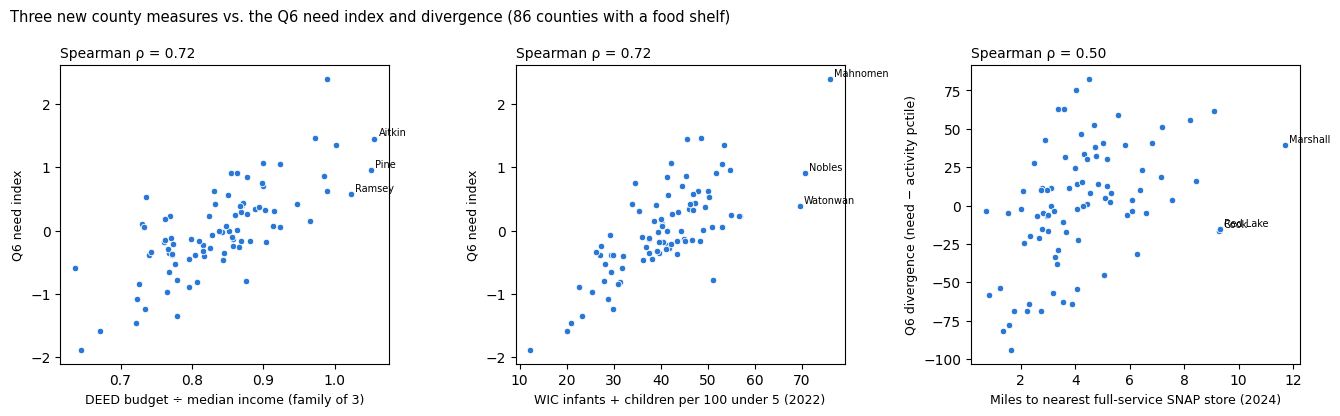

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.2))
pairs = [("col_affordability_gap_fam3", "need_ew", "DEED budget ÷ median income (family of 3)", "Q6 need index"),
         ("wic_infants_children_per_100_under5", "need_ew", "WIC infants + children per 100 under 5 (2022)", "Q6 need index"),
         ("snap_full_mean_dist_mi_2024", "div_combined", "Miles to nearest full-service SNAP store (2024)", "Q6 divergence (need − activity pctile)")]
for ax, (x, y, xl, yl) in zip(axes, pairs):
    ax.scatter(look[x], look[y], s=22, color="#2a78d6", edgecolor="white", linewidth=0.6)
    r = look[x].corr(look[y], method="spearman")
    ax.set_xlabel(xl, fontsize=9); ax.set_ylabel(yl, fontsize=9); ax.set_title(f"Spearman ρ = {r:.2f}", loc="left", fontsize=10)
    for f in look[x].nlargest(3).index:
        ax.annotate(COUNTY[f], (look.loc[f, x], look.loc[f, y]), fontsize=7, xytext=(3, 2), textcoords="offset points")
fig.suptitle("Three new county measures vs. the Q6 need index and divergence (86 counties with a food shelf)", x=0.01, ha="left", fontsize=10.5)
fig.tight_layout()
(ROOT / "outputs" / "q6").mkdir(parents=True, exist_ok=True)
fig.savefig(ROOT / "outputs" / "q6" / "q6_extra_factors_first_look.png", dpi=200, bbox_inches="tight"); plt.show()

## 7. Summary

- **DEED cost of living**: 87 counties (+ state and 19 regions), 24 family types, **one edition with no year in the file**: a cross-section only. The **affordability gap** (family-of-3 budget ÷ median income, 0.64–1.06) is strongly tied to the Q6 need index (ρ ≈ 0.72); the budget itself is not (−0.22).
- **SNAP retailers**: exact counts by store type for every county on 1 July 2022–2025 (3,510 → 3,612 statewide), openings/closings (net +102), and distance to the nearest full-service SNAP store (median county 4.0 miles; Red Lake has none). Ends December 2025 (asserted). The **retailer density and distance both line up with divergence** (ρ ≈ +0.46 and +0.50) but also with need, so they are tested properly (holding need fixed) in Q6 section 13f.
- **WIC**: extracted cleanly from all three PDFs. **2020–2022 only**, so it overlaps the food shelf data in 2022 alone. WIC uptake per young child tracks the need index closely (ρ ≈ 0.72) and not food shelf activity (ρ ≈ 0.03): consistent with need being real where food shelf activity is low.

These are first-look correlations; the tests (with multiple-testing correction and models) are in `01b_q1_factor_extension.ipynb` (section 8c) and `06_q6_divergence.ipynb` (sections 12c, 13f).